# GARCH, ML, or both? When each one wins
**ECON 422: Macroeconomics & Machine Learning**

We compare three ways to forecast tomorrow's uncertainty (variance):

| Forecaster | How it works |
|---|---|
| **GARCH** | a fixed straight-line rule: $\sigma_t^2=\omega+\alpha\,\varepsilon_{t-1}^2+\beta\,\sigma_{t-1}^2$ |
| **ML alone** | machine learning predicts the variance from the last few weeks of returns |
| **Hybrid** | GARCH's forecast $\times$ a correction factor learned by ML |

### The key idea: memory versus flexibility
**GARCH has long memory.** The term $\beta\,\sigma_{t-1}^2$ is a *recursive channel*: yesterday's variance was built from the day before, and so on, so today's forecast carries **all** past history, with older days fading gradually. But its rule is **rigid**: it squares the shock, so a fall and a rise of the same size always have the same effect.

**ML alone is flexible.** It can learn that falls matter more than rises, or any other shape. But it has **short memory**: it only sees the inputs we give it (here, the last 20 days).

**The hybrid** starts from GARCH's forecast, which brings in the long memory, and lets ML correct its shape.

### So who should win?
Each forecaster pays a cost:

| | Cost | Gets bigger when |
|---|---|---|
| GARCH | wrong **shape** | falls and rises have very different effects |
| ML alone | missing **memory** | turbulence lasts much longer than ML's 20-day window |
| Hybrid | neither (in principle) | — |

| Case | Data | Memory | Falls vs. rises | Prediction |
|---|---|---|---|---|
| 1 | artificial | short | very different | ML alone beats GARCH |
| 2 | artificial | very long | slightly different | GARCH beats ML alone |
| 3 | S&P 500 | long | clearly different | ? |

We judge the forecasters with **two scores**, the **penalty** and the **RMSE** (both explained below). In the artificial markets we know the true variance, so we can see exactly how far each forecast is from the truth.

In [1]:
# Run once if these packages are missing
%pip install -q arch scikit-learn matplotlib pandas numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


---
## The toolkit
All tools are in **one code cell** below; run it once. Most of the work is done by two libraries: **`arch`** (GARCH) and **`scikit-learn`** (ML and scores).

**Two scores** (lower is better for both):
- **Penalty** $=\text{average of}\left[\log h_t+\varepsilon_t^2/h_t\right]$, where $h_t$ is the forecast and $\varepsilon_t^2$ the squared shock that actually happened. It is the score used to estimate GARCH, and it needs no true variance. It judges each error *relative to the forecast*. It can be negative; only comparisons matter.
- **RMSE** $=\sqrt{\text{average of }(h_t-\text{actual variance}_t)^2}$, from scikit-learn. It needs the actual variance: the **true variance** in artificial markets, an **estimate** in real data (Case 3). It judges errors in *absolute size*, so a few big misses count a lot.

**What ML sees** (`make_ml_inputs`): five numbers known by yesterday. `.shift(1)` makes sure only past days are used.

| Input | What it tells ML |
|---|---|
| `yesterday` | yesterday's shock, **with its sign**: a fall or a rise? |
| `past_week`, `past_month` | sum of the last 5 / 20 shocks: has the market been falling? |
| `size_week`, `size_month` | average size of the last 5 / 20 shocks: has the market been wild? |

**GARCH** (`garch_forecast`): estimate $\omega,\alpha,\beta$ on the fitting years, then apply the rule to every day with those numbers frozen.

**ML** (`fit_trees`): *boosted trees*, many small decision trees added one at a time, each asking at most two yes/no questions. `loss="gamma"` makes them minimize a score with the same formula as our penalty. `GridSearchCV` tries several numbers of trees, keeps the one that scores best on the **validation** days, and refits on training + validation days.

**Running all three** (`run_three_forecasters`):
- **ML alone** predicts the squared shock directly.
- **Hybrid** predicts the ratio *squared shock / GARCH forecast*, then multiplies GARCH's forecast by it. A ratio above 1 means GARCH predicts too little uncertainty in that situation; below 1, too much.
- Data are split in time order: training, then validation (to choose the number of trees), then test (the final comparison).

**Artificial markets** (`simulate_market`): `arch` can simulate a market with these settings: a **base** variance, an **extra effect after a fall** (rises get none), **memory** (how much of yesterday's variance carries over), and optionally an effect **after any shock** (falls and rises alike; zero unless set).

In [1]:
# Copy and paste from Quizzes '[Week12] (Nov11) Exercise'.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from arch import arch_model
from arch.univariate import ZeroMean, GARCH, Normal
from arch.data import sp500
from regex import search
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.metrics import root_mean_squared_error as rmse

from Macroeconomic_analysis_studio_with_llm_prompt_writing.studio_core.workflow import forecast

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
MODELS = ["GARCH", "ML alone", "Hybrid"]


def penalty(squared_shock, forecast):
    return np.mean(np.log(forecast) + squared_shock / forecast)


def make_ml_inputs(shocks):
    return pd.DataFrame({
    "yesterday": shocks.shift(1),
    "past_week": shocks.rolling(5).sum().shift(1),
    "past_month": shocks.rolling(20).sum().shift(1),
    "size_week": shocks.abs().rolling(5).mean().shift(1),
    "size_month": shocks.abs().rolling(20).mean().shift(1),
    })


def garch_forecast(shocks, n_fit_days):
    numbers = arch_model(shocks[:n_fit_days], mean="Zero").fit(disp="off").params # estimate
    forecast = arch_model(shocks, mean="Zero").fix(numbers).conditional_volatility ** 2 # apply to all days
    return forecast, numbers


def fit_trees(inputs, target, n_train, n_valid):
    trees = HistGradientBoostingRegressor(loss="gamma", learning_rate=0.1, max_depth=2,
    min_samples_leaf=300, random_state=0)
    split = PredefinedSplit(np.r_[np.full(n_train, -1), np.zeros(n_valid)]) # -1 = training day, 0 = validation day
    search = GridSearchCV(trees, {"max_iter": [10, 25, 50, 100, 200, 400]},
    cv=split, scoring="neg_mean_gamma_deviance")
    n = n_train + n_valid
    return search.fit(inputs[:n], target[:n]) # also refits on training + validation days


def run_three_forecasters(shocks, n_train, n_valid, actual_variance):
    squared_shock = np.maximum(shocks[skip:] ** 2, 1e-8) # tiny floor: a few shocks are exactly zero
    n_train -= skip

    ml_alone = fit_trees(inputs, squared_shock, n_train, n_valid).predict(inputs)
    hybrid = garch * fit_trees(inputs, squared_shock / garch, n_train, n_valid).predict(inputs)

    test = slice(n_train + n_valid, None)
    forecasts = pd.DataFrame({"GARCH": garch, "ML alone": ml_alone, "Hybrid": hybrid, "Actual": actual})[test]
    scores = pd.DataFrame({
    "Penalty": [penalty(squared_shock[test], forecasts[m]) for m in MODELS],
    "RMSE": [rmse(forecasts["Actual"], forecasts[m]) for m in MODELS]}, index=MODELS).round(3)
    scores.insert(1, "Rank (penalty)", scores["Penalty"].rank().astype(int))
    scores["Rank (RMSE)"] = scores["RMSE"].rank().astype(int)
    return scores, forecasts.reset_index(drop=True), garch_numbers


def simulate_market(base, extra_after_fall, memory, after_any_shock=0.0, n_days=20000, seed=0):
    market = ZeroMean(volatility=GARCH(p=1, o=1, q=1), distribution=Normal(seed=np.random.default_rng(seed)))
    sim = market.simulate([base, after_any_shock, extra_after_fall, memory], nobs=n_days, burn=500)
    return sim["data"], sim["volatility"] ** 2


def plot_forecasts(forecasts, start, length, title, actual_label="True variance"):
    w = forecasts[start:start + length].reset_index(drop=True)
    plt.figure(figsize=(8, 3.4))
    plt.plot(w["Actual"], color="0.75", lw=2.5, label=actual_label)
    plt.plot(w["GARCH"], color="0.35", ls="--", label="GARCH")
    plt.plot(w["ML alone"], color="#C0703A", label="ML alone")
    plt.plot(w["Hybrid"], color="#1C557D", lw=1.6, label="Hybrid")
    plt.xlabel("Day in this window"); plt.ylabel("Variance"); plt.title(title)
    plt.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2))
    plt.show()

ModuleNotFoundError: No module named 'studio_core'

---
## Case 1: short memory, falls and rises very different
**Prediction: ML alone beats GARCH.**

```
variance today = 0.4
               + 0.4 × (yesterday's shock)²    only if yesterday was a FALL
               + 0.3 × yesterday's variance
```
- **Falls matter, rises do not.** GARCH cannot represent this, so it pays a **shape cost**.
- **Memory is short.** A shock's influence is 30% after one day, 9% after two, and almost zero after five: well inside ML's 20-day window, so ML pays **no memory cost**.

Each artificial market has 20,000 days: 10,000 for training, 5,000 for validation, 5,000 for testing.

GARCH's estimated numbers: {'omega': 0.389, 'alpha[1]': 0.203, 'beta[1]': 0.307}


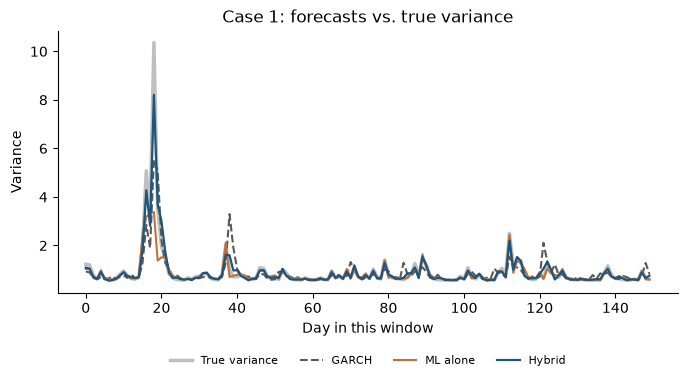

In [3]:
shocks1, true_var1 = simulate_market(base=0.4, extra_after_fall=0.4, memory=0.3)
scores1, forecasts1, garch1 = run_three_forecasters(shocks1, n_train=10000, n_valid=5000, actual_variance=true_var1)
print("GARCH's estimated numbers:", garch1.round(3).to_dict())
plot_forecasts(forecasts1, start=2990, length=150, title="Case 1: forecasts vs. true variance")

In [4]:
scores1      # test days; lower is better

,Penalty,Rank (penalty),RMSE,Rank (RMSE)
GARCH,0.698,3,0.336,3
ML alone,0.670,2,0.218,2
Hybrid,0.669,1,0.136,1


**Reading the table.**
- **ML alone beats GARCH on both scores**, by a wide margin on RMSE (0.22 vs. 0.34).
- **The hybrid is clearly best on RMSE** (0.14) and **ties ML alone on the penalty**. With short memory, GARCH's long-memory starting point adds little on ordinary days; its advantage shows on the biggest spikes, which RMSE weighs heavily.

**Why GARCH loses.** It must use **one** $\alpha$ for falls and rises, so it splits the difference:

| | True market | GARCH's estimate |
|---|---|---|
| Effect of a fall | 0.4 | 0.20 |
| Effect of a rise | 0 | 0.20 |
| Memory | 0.3 | 0.31 |

It gets the memory right but the shape wrong: it **underreacts after every fall and raises false alarms after every rise**.

**In the plot.** This window contains the largest spike in the test period.
- **GARCH** (dashed) shows bumps where the true variance (thick gray) stays flat (false alarms after rises), and catches only part of each spike after a fall.
- **ML alone** (orange) avoids the false alarms but falls short on the biggest spike: such large falls are rare in training.
- **Hybrid** (blue) follows the truth most closely, including the big spike: GARCH's forecast already grows with the size of a shock, and ML only adds the fall-versus-rise correction.

---
## Case 2: very long memory, falls and rises slightly different
**Prediction: GARCH beats ML alone.**

```
variance today = 0.01
               + 0.04 × (yesterday's shock)²   only if yesterday was a FALL
               + 0.97 × yesterday's variance
```
- **Falls matter slightly more**, so GARCH's **shape cost is small**.
- **Memory is very long.** 97% of yesterday's variance carries over, so a shock still has $0.97^{20}\approx54\%$ of its influence after 20 days. More than half of it is **outside ML's window**: a **large memory cost**. GARCH's recursive channel $\beta\,\sigma^2_{t-1}$ carries all of it.

GARCH's estimated numbers: {'omega': 0.012, 'alpha[1]': 0.026, 'beta[1]': 0.961}


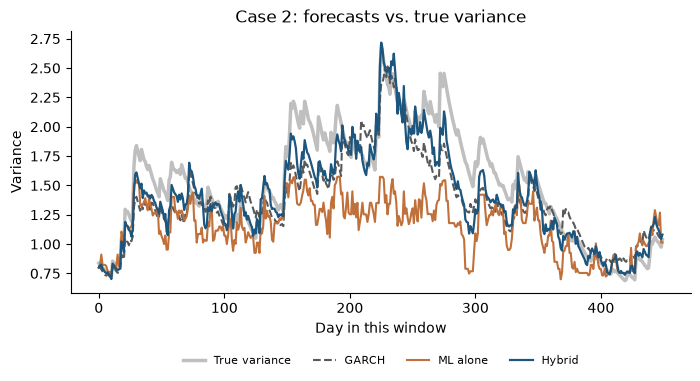

In [5]:
shocks2, true_var2 = simulate_market(base=0.01, extra_after_fall=0.04, memory=0.97)
scores2, forecasts2, garch2 = run_three_forecasters(shocks2, n_train=10000, n_valid=5000, actual_variance=true_var2)
print("GARCH's estimated numbers:", garch2.round(3).to_dict())
plot_forecasts(forecasts2, start=3650, length=450, title="Case 2: forecasts vs. true variance")

In [6]:
scores2      # test days; lower is better

,Penalty,Rank (penalty),RMSE,Rank (RMSE)
GARCH,0.871,2,0.133,2
ML alone,0.879,3,0.187,3
Hybrid,0.868,1,0.093,1


**Reading the table.** Both scores agree: **Hybrid 1st, GARCH 2nd, ML alone 3rd**. ML alone's RMSE is about 40% higher than GARCH's.

**Why GARCH beats ML alone.** GARCH's estimated memory $\beta\approx0.96$ (with $\alpha+\beta\approx0.99$) matches the market. ML alone, limited to 20 days, cannot tell "calm this month but wild three months ago" from "calm all along".

**Why the hybrid still wins.** It takes GARCH's long memory as its starting point and adds the small fall-versus-rise correction that GARCH misses.

**In the plot.** This window contains the most turbulent stretch of the test period.
- **ML alone** (orange) **stays too low** through the long turbulent stretch (days 150–300): about 1.0–1.5 while the truth is 1.5–2.5. The turbulence built up over months, beyond its 20-day window. It is also jumpier, reacting to each week.
- **GARCH** (dashed) rises and falls with the slow waves, because its variance builds on itself day after day, though it also runs a little low at times.
- **Hybrid** (blue) follows the waves like GARCH and stays closest to the truth.

---
## Case 3: real S&P 500 returns
Real stock markets have **long memory** (like Case 2) **and** a **clear fall-versus-rise difference** (like Case 1). Training: 1999–2006. Validation: 2007–2010. Test: 2011–2018.

### What do we compare with? An estimate of the actual variance
In real data the true variance is **never observed**: each day we see one return, not the distribution it came from. The squared shock is one noisy draw: a calm day can produce a big move by chance.

A better estimate uses the day's **trading range**, the gap between the day's highest and lowest price: a wild day swings widely within the day. A standard formula turns the range into a variance estimate:
$$\text{estimate}_t=\frac{\big(100\,\log(\text{High}_t/\text{Low}_t)\big)^2}{4\log 2}.$$
The range misses moves **overnight** (between one day's close and the next day's open), so we scale it up to match the average squared shock in the training years. We use this estimate for RMSE and the plot; the penalty, as always, uses the squared shock.

GARCH's estimated numbers: {'omega': 0.012, 'alpha[1]': 0.074, 'beta[1]': 0.919}


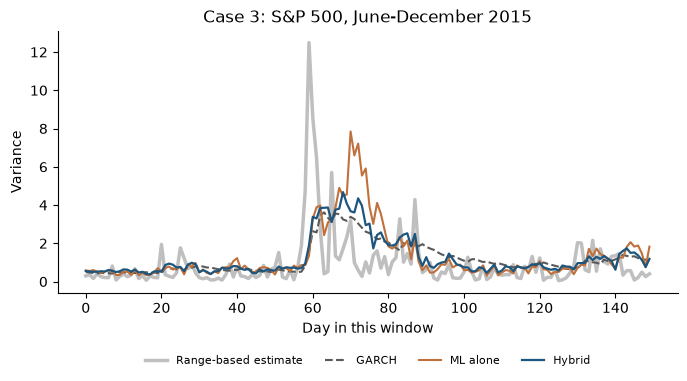

In [7]:
prices = sp500.load()
returns = 100 * np.log(prices["Adj Close"]).diff().dropna()          # daily return in %
shocks3 = returns - returns[returns.index < "2011-01-01"].mean()     # shock = return minus its average
n_train = int((returns.index < "2007-01-01").sum())
n_valid = int(((returns.index >= "2007-01-01") & (returns.index < "2011-01-01")).sum())

# Range-based estimate of each day's variance, scaled up for overnight moves
day_range = 100 * np.log(prices["High"] / prices["Low"]).loc[returns.index]
range_estimate = day_range**2 / (4 * np.log(2))
range_estimate *= (shocks3[:n_train]**2).mean() / range_estimate[:n_train].mean()

scores3, forecasts3, garch3 = run_three_forecasters(shocks3, n_train, n_valid, actual_variance=range_estimate)
print("GARCH's estimated numbers:", garch3.round(3).to_dict())

test_dates = returns.index[-len(forecasts3):]
start = int(np.argmax(test_dates >= "2015-06-01"))                   # first test day in June 2015
plot_forecasts(forecasts3, start, 150, "Case 3: S&P 500, June-December 2015", actual_label="Range-based estimate")

In [8]:
scores3      # test days 2011-2018; lower is better

,Penalty,Rank (penalty),RMSE,Rank (RMSE)
GARCH,0.548,3,1.194,2
ML alone,0.529,2,1.265,3
Hybrid,0.493,1,1.148,1


**Reading the table.**
- **The hybrid wins on both scores.**
- **GARCH vs. ML alone is a split decision:** ML alone wins on the penalty, GARCH on RMSE.

**Why the split?** Real stocks have **long memory** ($\alpha+\beta\approx0.99$), which hurts ML alone, and a **clear fall-versus-rise difference**, which hurts GARCH.
- On **ordinary days**, ML alone's fall-versus-rise shape makes it more accurate *relative to the level of variance*. The penalty rewards that.
- In **sell-offs**, ML alone overreacts to the latest week, producing errors that are large in absolute size. RMSE punishes those heavily.

**In the plot.** The gray line jumps to about 12 on August 24, 2015 (around day 59), the day of the sell-off.
- **No forecaster sees that first spike coming:** each forecast is made the day before, and the sell-off was a surprise.
- **ML alone** (orange) then overreacts, climbing to 6–8 about ten days later, when the estimate has already fallen back to 1–3.
- **GARCH** (dashed) rises less but stays high too long into October.
- **Hybrid** (blue) sits in between and falls back sooner than GARCH.

---
## Summary table: all results in one place

In [9]:
summary = pd.concat({"Case 1 (short memory)": scores1,
                     "Case 2 (very long memory)": scores2,
                     "Case 3 (S&P 500)": scores3})
summary[["Penalty", "RMSE"]].unstack().round(3)      # rows: cases; columns: score and forecaster

Penalty                   RMSE                
                            GARCH ML alone Hybrid  GARCH ML alone Hybrid
Case 1 (short memory)       0.698    0.670  0.669  0.336    0.218  0.136
Case 2 (very long memory)   0.871    0.879  0.868  0.133    0.187  0.093
Case 3 (S&P 500)            0.548    0.529  0.493  1.194    1.265  1.148

## When does each one win?

| Case | Memory | Falls vs. rises | GARCH's shape cost | ML's memory cost | GARCH vs. ML alone | Best |
|---|---|---|---|---|---|---|
| 1 | short | very different | large | none | **ML alone wins** on both scores | Hybrid (RMSE); tie with ML alone (penalty) |
| 2 | very long | slightly different | small | large | **GARCH wins** on both scores | Hybrid on both |
| 3 (S&P 500) | long | clearly different | large | moderate | **split**: ML alone by penalty, GARCH by RMSE | Hybrid on both |

### Rules of thumb
- **GARCH beats ML alone** when uncertainty has long memory and GARCH's same-for-falls-and-rises rule is roughly right. Its recursive channel $\beta\,\sigma^2_{t-1}$ remembers all of the past in one number.
- **ML alone beats GARCH** when the true rule has a shape GARCH cannot represent and the history that matters fits inside ML's inputs.
- **The hybrid is best or tied in every case**, because it pays neither cost: GARCH supplies the memory, ML corrects the shape.
- **When the two scores disagree, look at where each model makes its errors.** On the S&P, ML alone is better on ordinary days but overreacts in sell-offs.
- **Flexibility cannot replace missing information.** ML alone's weakness is not that it is ML; its inputs stop at 20 days.